# STN — Sparse attention-based Transformer Networks para pronóstico de PM2.5

Réplica ejecutable del modelo del paper de referencia:

> Zhang, Z. & Zhang, S. (2023). *Modeling air quality PM2.5 forecasting using deep sparse
> attention-based transformer networks*. **Int. J. Environ. Sci. Technol.** 20, 13535–13550.
> DOI: [10.1007/s13762-023-04900-1](https://doi.org/10.1007/s13762-023-04900-1)

Este cuaderno continúa donde termina `Baseline_PM25_Fontibon_3Fases`: allí el modelo era un
Random Forest y el objetivo era comparar estrategias de datos faltantes; acá el modelo es el STN
del paper y el objetivo es (a) verificar que la implementación reproduce los números publicados,
(b) buscar hiperparámetros honestamente y (c) entrenarlo sobre FONTIBÓN.

## Punto de partida: qué existe y qué no

| Pregunta | Respuesta |
|---|---|
| ¿Hay pesos preentrenados del STN? | **No.** Los autores no publicaron código ni modelo. |
| ¿Están los datos del paper? | Beijing sí (Kaggle/UCI). Taizhou **no** — es privado de los autores. |
| ¿Está la arquitectura en el paper? | **Parcialmente** (ver tabla de la Sección 3). |
| ¿Es replicable? | Sí: el paper describe los bloques y cita a Informer como base de la atención dispersa. |

## Qué NO es este cuaderno

No es un fine-tuning de un modelo ajeno. Es una implementación propia, y por eso el **primer paso
obligatorio es la Sección 5**: reproducir el resultado publicado en Beijing. Si eso no da, cualquier
número sobre Bogotá es ruido de un bug, no evidencia sobre tus datos.

## Orden de ejecución

1. Secciones 1–4: configuración, datos, arquitectura, utilidades. **Siempre.**
2. Sección 5: validación en Beijing → esperás R² ≈ 0.937.
3. Sección 6: comparación de datasets (decide si Kaggle aporta algo).
4. Sección 7: búsqueda de hiperparámetros, **solo dentro del train**.
5. Sección 8: modelo final sobre FONTIBÓN, evaluado una sola vez sobre 2024.
6. Sección 9: transfer learning Beijing → Bogotá (opcional, hipótesis nula).

## Reglas no negociables (las mismas del cuaderno baseline)

1. Split **temporal**, nunca aleatorio.
2. El escalador se ajusta **solo** con train.
3. La validación es el tramo final del train, no un 10% aleatorio (el paper usa aleatorio; en serie
   horaria eso infla la métrica porque pone horas contiguas casi idénticas a ambos lados).
4. En test se evalúa **solo donde el PM2.5 real está observado**: las horas interpoladas entran como
   insumo del modelo, nunca como verdad de terreno.
5. Todo resultado del STN se reporta junto al baseline de **persistencia**.

---
## Sección 1: Entorno, librerías y configuración global

In [2]:
# Si estás en Colab, descomentá:
# !pip -q install torch pandas pyarrow

import math, json, random, time, warnings
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED); random.seed(SEED)

def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = get_device()
print("PyTorch:", torch.__version__, "| dispositivo:", DEVICE)

PyTorch: 2.13.0 | dispositivo: cuda


In [3]:
# ── Rutas ────────────────────────────────────────────────────────────────────
# Beijing: kaggle datasets download -d djhavera/beijing-pm25-data-data-set
#          (es el mismo archivo de UCI "Beijing PM2.5 Data" que enlaza el paper)
def localizar_archivo(nombre, en_data=False, obligatorio=False):
    """Busca archivos desde la raíz del proyecto, la carpeta del notebook y `modelos y bd`."""
    rutas = []
    cwd = Path.cwd().resolve()
    rutas.extend([cwd, *cwd.parents])
    rutas.extend([
        cwd / 'Proyecto---Deep-Learning',
        cwd / 'Proyecto---Deep Learning',
        cwd / 'modelos y bd',
        cwd / 'Proyecto---Deep-Learning' / 'modelos y bd',
        cwd / 'Proyecto---Deep Learning' / 'modelos y bd',
    ])

    vistas = set()
    for carpeta in rutas:
        carpeta = carpeta.resolve()
        if carpeta in vistas:
            continue
        vistas.add(carpeta)
        candidatos = [carpeta / nombre, carpeta / 'modelos y bd' / nombre]
        if en_data:
            candidatos += [carpeta / 'data' / nombre, carpeta / 'modelos y bd' / 'data' / nombre]
        for candidato in candidatos:
            if candidato.is_file():
                return candidato

    if obligatorio:
        raise FileNotFoundError(
            f'No se encontró {nombre}. Revisá que esté dentro de la carpeta del proyecto o en "modelos y bd".'
        )
    return Path('modelos y bd') / nombre

RUTA_BEIJING = localizar_archivo('PRSA_data_2010.1.1-2014.12.31.csv', en_data=True)
RUTA_BOGOTA  = localizar_archivo('bogota_calidad_aire_raw.parquet', obligatorio=True)
ESTACION     = "FONTIBÓN"

# ── Protocolo experimental (fijado por el paper) ─────────────────────────────
SEQ_LEN   = 24          # lookback: el paper lo fija en 24 h
PRED_LEN  = 1           # h1 = un paso adelante (Tabla 1 del paper)
LABEL_LEN = 12          # start tokens del decoder — NO está en el paper, es hiperparámetro

TEST_START_BEIJING = "2014-01-01"   # train 2010-2013 / test 2014
TEST_START_BOGOTA  = "2024-01-01"   # train 2020-2023 / test 2024
FECHA_INICIO_BOGOTA = "2020-01-01"
FECHA_FIN_BOGOTA    = "2025-01-01"

# ── Optimización (valores del paper) ─────────────────────────────────────────
LR         = 1e-4
BATCH_SIZE = 32
EPOCHS     = 30         # el paper dice máx. 200; con early stopping alcanza mucho menos
PATIENCE   = 8

# ── Variables ────────────────────────────────────────────────────────────────
BEIJING_FEATURES = ["pm2.5", "DEWP", "TEMP", "PRES", "Iws", "Is", "Ir",
                    "cbwd_NE", "cbwd_NW", "cbwd_SE", "cbwd_cv"]

BOGOTA_FEATURES_DEFAULT = ["PM2.5", "TAire2", "TAire10", "HAire2", "HAire10",
                           "P", "DViento", "VViento", "PLiquida"]

print("Configuración cargada.")

Configuración cargada.


---
## Sección 2: Datos

**Qué se hace:** una función de carga por fuente, y luego un camino común
(split temporal → imputación causal → escalado MinMax ajustado solo en train → ventaneo).

**Por qué el mismo camino para las dos:** si Beijing y Bogotá pasaran por preprocesamientos
distintos, la validación de la Sección 5 dejaría de decir algo sobre el código que corre en la
Sección 8.

**Sobre los faltantes:** el paper menciona interpolación lineal, pero no especifica si evita
información futura. Para que la evaluación sea operativa, acá se separa el tiempo primero y se usa
relleno hacia adelante limitado (`max_interp_gap`, 24 h); los huecos más largos reciben la mediana
del train. Las horas sin PM2.5 observado siguen excluidas de la evaluación.

In [4]:
def load_beijing(csv_path: str) -> pd.DataFrame:
    """Devuelve un DataFrame horario indexado por fecha con el target en 'pm2.5'."""
    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    df["fecha_hora"] = pd.to_datetime(
        dict(year=df["year"], month=df["month"], day=df["day"], hour=df["hour"])
    )
    df = df.set_index("fecha_hora").sort_index()

    # 'cbwd' (dirección combinada del viento) es categórica -> one-hot,
    # igual que hace cualquier réplica razonable del paper.
    dummies = pd.get_dummies(df["cbwd"], prefix="cbwd").astype("float32")
    df = pd.concat([df.drop(columns=["No", "year", "month", "day", "hour", "cbwd"]), dummies], axis=1)

    for col in BEIJING_FEATURES:
        if col not in df.columns:
            df[col] = 0.0
    df = df[BEIJING_FEATURES].astype("float32")
    return df


def load_bogota(parquet_path: str, estacion: str = "FONTIBÓN",
                variables=None, fecha_inicio="2020-01-01",
                fecha_fin_exclusiva="2025-01-01") -> pd.DataFrame:
    """Devuelve un DataFrame horario de la estación objetivo, columna target 'PM2.5'."""
    variables = list(variables or BOGOTA_FEATURES_DEFAULT)
    df = pd.read_parquet(parquet_path)

    es_largo = {"med_fecha_inicio", "msfl_code", "med_concentracion_estandar"}.issubset(df.columns)
    if es_largo:
        df["med_fecha_inicio"] = pd.to_datetime(df["med_fecha_inicio"])
        df["med_concentracion_estandar"] = pd.to_numeric(
            df["med_concentracion_estandar"], errors="coerce"
        )
        sub = df[(df["nombre_est"] == estacion) & (df["msfl_code"].isin(variables))]
        ancho = sub.pivot_table(
            index="med_fecha_inicio", columns="msfl_code",
            values="med_concentracion_estandar", aggfunc="mean",
        )
    else:
        ancho = df.copy()
        if not isinstance(ancho.index, pd.DatetimeIndex):
            ancho.index = pd.to_datetime(ancho.index)

    grilla = pd.date_range(fecha_inicio, fecha_fin_exclusiva, freq="h", inclusive="left")
    ancho = ancho.reindex(grilla)
    ancho.index.name = "fecha_hora"

    cols = [c for c in variables if c in ancho.columns]
    faltan = [c for c in variables if c not in ancho.columns]
    if faltan:
        print(f"[aviso] variables ausentes en el parquet y omitidas: {faltan}")
    return ancho[cols].astype("float32")

In [5]:
@dataclass
class PreparedData:
    train: np.ndarray
    val: np.ndarray
    test: np.ndarray
    test_target_observed: np.ndarray       # máscara de PM2.5 realmente observado en test
    scaler_min: np.ndarray
    scaler_max: np.ndarray
    target_idx: int
    feature_names: list = field(default_factory=list)
    test_index: pd.DatetimeIndex | None = None

    def inverse_target(self, y_scaled: np.ndarray) -> np.ndarray:
        lo = self.scaler_min[self.target_idx]
        hi = self.scaler_max[self.target_idx]
        return y_scaled * (hi - lo) + lo


def prepare(df: pd.DataFrame, target: str, fecha_corte_test: str,
            val_fraction: float = 0.1, max_interp_gap: int = 24,
            val_mode: str = "tail") -> PreparedData:
    """
    - Separa train, validación y test antes de imputar.
    - Rellena solo hacia adelante, limitado por `max_interp_gap`; nunca usa una
      observación futura. Los huecos largos usan la mediana del train.
    - Validación: último `val_fraction` cronológico del train.
    - MinMax a [0,1] ajustado SOLO con train.
    """
    if val_mode != "tail":
        raise ValueError("Solo se admite val_mode='tail': una validación aleatoria rompe la continuidad temporal.")
    df = df.copy()
    target_idx = list(df.columns).index(target)
    idx = df.index
    is_test = idx >= pd.Timestamp(fecha_corte_test)
    observed_target = df[target].notna().to_numpy()

    # Primero se separa el tiempo. La imputación nunca puede consultar una hora futura.
    train_val_raw, test_raw = df.loc[~is_test], df.loc[is_test]
    n_val = max(1, int(len(train_val_raw) * val_fraction))
    train_raw, val_raw = train_val_raw.iloc[:-n_val], train_val_raw.iloc[-n_val:]
    respaldo = train_raw.median(numeric_only=True).reindex(df.columns).fillna(0.0)

    def imputar_causal(bloque, contexto=None):
        # ffill limitado usa exclusivamente observaciones pasadas; los huecos largos usan la mediana de train.
        completo = bloque if contexto is None else pd.concat([contexto, bloque])
        completo = completo.ffill(limit=max_interp_gap).fillna(respaldo)
        resultado = completo.iloc[-len(bloque):]
        return resultado, completo.tail(1)

    train_df, contexto = imputar_causal(train_raw)
    val_df, contexto = imputar_causal(val_raw, contexto)
    test_df, _ = imputar_causal(test_raw, contexto)
    train = train_df.to_numpy(dtype="float32")
    val = val_df.to_numpy(dtype="float32")
    test = test_df.to_numpy(dtype="float32")
    test_obs = observed_target[is_test]

    lo = train.min(axis=0)
    hi = train.max(axis=0)
    rng_ = np.where(hi - lo == 0, 1.0, hi - lo)

    def scale(a):
        return ((a - lo) / rng_).astype("float32")

    return PreparedData(
        train=scale(train), val=scale(val), test=scale(test),
        test_target_observed=test_obs,
        scaler_min=lo, scaler_max=lo + rng_,
        target_idx=target_idx, feature_names=list(df.columns),
        test_index=idx[is_test],
    )

In [6]:
class WindowDataset(Dataset):
    """Ventanas (encoder, decoder, target) al estilo Informer/STN.

    encoder: x[i : i+seq_len]  (todas las variables)
    decoder: [start tokens de longitud label_len] + [ceros de longitud pred_len]
    target : PM2.5 de las pred_len horas siguientes
    """

    def __init__(self, data: np.ndarray, seq_len: int, label_len: int, pred_len: int,
                 target_idx: int, observed_mask: np.ndarray | None = None):
        self.data = data
        self.seq_len = seq_len
        self.label_len = label_len
        self.pred_len = pred_len
        self.target_idx = target_idx
        self.observed_mask = observed_mask
        self.n = len(data) - seq_len - pred_len + 1
        if self.n <= 0:
            raise ValueError("Serie demasiado corta para seq_len + pred_len.")

    def __len__(self):
        return self.n

    def __getitem__(self, i):
        s_end = i + self.seq_len
        r_begin = s_end - self.label_len
        r_end = s_end + self.pred_len

        x_enc = self.data[i:s_end]
        dec_hist = self.data[r_begin:s_end]
        dec_zeros = np.zeros((self.pred_len, self.data.shape[1]), dtype="float32")
        x_dec = np.concatenate([dec_hist, dec_zeros], axis=0)
        y = self.data[s_end:r_end, self.target_idx:self.target_idx + 1]

        obs = (np.ones(self.pred_len, dtype="float32")
               if self.observed_mask is None
               else self.observed_mask[s_end:r_end].astype("float32"))

        return (torch.from_numpy(x_enc), torch.from_numpy(x_dec),
                torch.from_numpy(y), torch.from_numpy(obs))

---
## Sección 3: Arquitectura del STN

**La pregunta previa: ¿la arquitectura está en el paper o hay que inducirla?** Ambas cosas.

| Componente | ¿En el paper? | Valor usado acá |
|---|---|---|
| Encoder–decoder con position embedding senoidal | Sí | — |
| Atención dispersa (medida K-L, muestreo de keys, top-*u* queries, O(L·log L)) | Sí, con ecuaciones | — |
| Destilación Conv1D k=3 + max-pool stride 2 | Sí | — |
| Encoder de **dos ramas** (una recibe ½·Lx) | Sí | — |
| Decoder: atención dispersa enmascarada + atención estándar cruzada + FFN + lineal | Sí | — |
| Nº de capas | Sí | 3 encoders, 2 decoders |
| Lookback | Sí | 24 h |
| Adam, lr 1e-4, batch 32, ≤200 épocas, MSE, datos en [0,1] | Sí | — |
| `d_model`, `n_heads`, `d_ff`, dropout, factor *c*, `label_len` | **No** | defaults de Informer: 512, 8, 2048, 0.05, 5 |
| Codificación de la dirección del viento | No | one-hot |
| Normalización por variable vs. global | No | MinMax por variable, solo train |

Todo lo que está en la fila "No" es exactamente lo que va a la búsqueda de la Sección 7: no hay
valor publicado que replicar, así que fijarlo a ojo sería una decisión arbitraria disfrazada de
réplica.

**De dónde sale lo que el paper no dice:** el propio paper cita a Informer (Zhou et al., AAAI 2021)
como origen del mecanismo de atención dispersa, así que los defaults de Informer son la elección
defendible por escrito en la tesis, no una invención.

### 3.1 Embeddings

In [7]:
class PositionalEmbedding(nn.Module):
    """Position embedding senoidal (el paper lo menciona explícitamente)."""

    def __init__(self, d_model: int, max_len: int = 5000):
        super().__init__()
        pe = torch.zeros(max_len, d_model).float()
        pe.require_grad = False
        position = torch.arange(0, max_len).float().unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * -(math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe.unsqueeze(0))

    def forward(self, x):
        return self.pe[:, : x.size(1)]


class TokenEmbedding(nn.Module):
    """Proyección de las c_in variables a d_model con una Conv1D causal-circular."""

    def __init__(self, c_in: int, d_model: int):
        super().__init__()
        self.tokenConv = nn.Conv1d(
            in_channels=c_in, out_channels=d_model, kernel_size=3,
            padding=1, padding_mode="circular", bias=False,
        )
        for m in self.modules():
            if isinstance(m, nn.Conv1d):
                nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="leaky_relu")

    def forward(self, x):
        return self.tokenConv(x.permute(0, 2, 1)).transpose(1, 2)


class TimeFeatureEmbedding(nn.Module):
    """Embedding de marcas temporales (hora, día, día-semana, mes) normalizadas.

    El paper NO lo menciona; queda desactivado por defecto (`use_time_features=False`)
    para mantener la réplica fiel. Actívalo solo como experimento extra y
    documéntalo como desviación respecto del paper.
    """

    def __init__(self, d_model: int, n_time_feats: int = 4):
        super().__init__()
        self.embed = nn.Linear(n_time_feats, d_model, bias=False)

    def forward(self, x_mark):
        return self.embed(x_mark)


class DataEmbedding(nn.Module):
    def __init__(self, c_in, d_model, dropout=0.05, use_time_features=False, n_time_feats=4):
        super().__init__()
        self.value_embedding = TokenEmbedding(c_in, d_model)
        self.position_embedding = PositionalEmbedding(d_model)
        self.use_time_features = use_time_features
        if use_time_features:
            self.temporal_embedding = TimeFeatureEmbedding(d_model, n_time_feats)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, x_mark=None):
        out = self.value_embedding(x) + self.position_embedding(x)
        if self.use_time_features and x_mark is not None:
            out = out + self.temporal_embedding(x_mark)
        return self.dropout(out)

### 3.2 Máscaras

In [8]:
class TriangularCausalMask:
    def __init__(self, B, L, device="cpu"):
        mask_shape = [B, 1, L, L]
        with torch.no_grad():
            self._mask = torch.triu(
                torch.ones(mask_shape, dtype=torch.bool, device=device), diagonal=1
            )

    @property
    def mask(self):
        return self._mask


class ProbMask:
    """Máscara causal restringida a las top-u queries seleccionadas."""

    def __init__(self, B, H, L, index, scores, device="cpu"):
        _mask = torch.ones(L, scores.shape[-1], dtype=torch.bool, device=device).triu(1)
        _mask_ex = _mask[None, None, :].expand(B, H, L, scores.shape[-1])
        indicator = _mask_ex[
            torch.arange(B)[:, None, None], torch.arange(H)[None, :, None], index, :
        ]
        self._mask = indicator.view(scores.shape).to(device)

    @property
    def mask(self):
        return self._mask

### 3.3 Atención (dispersa y estándar)

In [9]:
class FullAttention(nn.Module):
    """Atención estándar O(L^2). El paper la usa en la atención CRUZADA del decoder."""

    def __init__(self, mask_flag=True, scale=None, attention_dropout=0.05):
        super().__init__()
        self.scale = scale
        self.mask_flag = mask_flag
        self.dropout = nn.Dropout(attention_dropout)

    def forward(self, queries, keys, values, attn_mask=None):
        B, L, H, E = queries.shape
        scale = self.scale or 1.0 / math.sqrt(E)
        scores = torch.einsum("blhe,bshe->bhls", queries, keys)
        if self.mask_flag:
            if attn_mask is None:
                attn_mask = TriangularCausalMask(B, L, device=queries.device)
            scores.masked_fill_(attn_mask.mask, -np.inf)
        A = self.dropout(torch.softmax(scale * scores, dim=-1))
        V = torch.einsum("bhls,bshd->blhd", A, values)
        return V.contiguous()


class ProbAttention(nn.Module):
    """Atención dispersa multi-head (ec. 5-7 del paper): medida de esparsidad
    aproximada por muestreo de keys + selección de las top-u queries."""

    def __init__(self, mask_flag=True, factor=5, scale=None, attention_dropout=0.05):
        super().__init__()
        self.factor = factor
        self.scale = scale
        self.mask_flag = mask_flag
        self.dropout = nn.Dropout(attention_dropout)

    def _prob_QK(self, Q, K, sample_k, n_top):
        B, H, L_K, E = K.shape
        _, _, L_Q, _ = Q.shape

        # Muestreo aleatorio de keys (K~ de la ec. 7)
        K_expand = K.unsqueeze(-3).expand(B, H, L_Q, L_K, E)
        index_sample = torch.randint(L_K, (L_Q, sample_k), device=K.device)
        K_sample = K_expand[:, :, torch.arange(L_Q).unsqueeze(1), index_sample, :]
        Q_K_sample = torch.matmul(Q.unsqueeze(-2), K_sample.transpose(-2, -1)).squeeze(-2)

        # M_sparse = max - media  (aprox. de la K-L divergence contra la uniforme)
        M = Q_K_sample.max(-1)[0] - torch.div(Q_K_sample.sum(-1), sample_k)
        M_top = M.topk(n_top, sorted=False)[1]

        Q_reduce = Q[
            torch.arange(B)[:, None, None], torch.arange(H)[None, :, None], M_top, :
        ]
        Q_K = torch.matmul(Q_reduce, K.transpose(-2, -1))
        return Q_K, M_top

    def _get_initial_context(self, V, L_Q):
        B, H, L_V, D = V.shape
        if not self.mask_flag:
            V_sum = V.mean(dim=-2)
            context = V_sum.unsqueeze(-2).expand(B, H, L_Q, V_sum.shape[-1]).clone()
        else:
            assert L_Q == L_V, "self-attention enmascarada requiere L_Q == L_V"
            context = V.cumsum(dim=-2)
        return context

    def _update_context(self, context_in, V, scores, index, L_Q):
        B, H, L_V, D = V.shape
        if self.mask_flag:
            attn_mask = ProbMask(B, H, L_Q, index, scores, device=V.device)
            scores.masked_fill_(attn_mask.mask, -np.inf)
        attn = torch.softmax(scores, dim=-1)
        context_in[
            torch.arange(B)[:, None, None], torch.arange(H)[None, :, None], index, :
        ] = torch.matmul(attn, V).type_as(context_in)
        return context_in

    def forward(self, queries, keys, values, attn_mask=None):
        B, L_Q, H, D = queries.shape
        _, L_K, _, _ = keys.shape

        queries = queries.transpose(2, 1)
        keys = keys.transpose(2, 1)
        values = values.transpose(2, 1)

        U_part = self.factor * int(math.ceil(math.log(max(L_K, 2))))
        u = self.factor * int(math.ceil(math.log(max(L_Q, 2))))
        U_part = min(U_part, L_K)
        u = min(u, L_Q)

        scores_top, index = self._prob_QK(queries, keys, sample_k=U_part, n_top=u)
        scale = self.scale or 1.0 / math.sqrt(D)
        scores_top = scores_top * scale

        context = self._get_initial_context(values, L_Q)
        context = self._update_context(context, values, scores_top, index, L_Q)
        return context.transpose(2, 1).contiguous()


class AttentionLayer(nn.Module):
    def __init__(self, attention, d_model, n_heads, d_keys=None, d_values=None, mix=False):
        super().__init__()
        d_keys = d_keys or (d_model // n_heads)
        d_values = d_values or (d_model // n_heads)
        self.inner_attention = attention
        self.query_projection = nn.Linear(d_model, d_keys * n_heads)
        self.key_projection = nn.Linear(d_model, d_keys * n_heads)
        self.value_projection = nn.Linear(d_model, d_values * n_heads)
        self.out_projection = nn.Linear(d_values * n_heads, d_model)
        self.n_heads = n_heads
        self.mix = mix

    def forward(self, queries, keys, values, attn_mask=None):
        B, L, _ = queries.shape
        _, S, _ = keys.shape
        H = self.n_heads

        queries = self.query_projection(queries).view(B, L, H, -1)
        keys = self.key_projection(keys).view(B, S, H, -1)
        values = self.value_projection(values).view(B, S, H, -1)

        out = self.inner_attention(queries, keys, values, attn_mask)
        if self.mix:
            out = out.transpose(2, 1).contiguous()
        out = out.view(B, L, -1)
        return self.out_projection(out)

### 3.4 Encoder (bloques, destilación y las dos ramas)

In [10]:
class ConvLayer(nn.Module):
    """Destilación: Conv1D (kernel 3) + ELU + max-pooling stride 2 — tal cual el paper."""

    def __init__(self, c_in):
        super().__init__()
        self.downConv = nn.Conv1d(
            in_channels=c_in, out_channels=c_in, kernel_size=3,
            padding=1, padding_mode="circular",
        )
        self.norm = nn.BatchNorm1d(c_in)
        self.activation = nn.ELU()
        self.maxPool = nn.MaxPool1d(kernel_size=3, stride=2, padding=1)

    def forward(self, x):
        x = self.downConv(x.permute(0, 2, 1))
        x = self.norm(x)
        x = self.activation(x)
        x = self.maxPool(x)
        return x.transpose(1, 2)


class EncoderLayer(nn.Module):
    """Bloque de atención dispersa: MHSA disperso + FFN, residual + LayerNorm."""

    def __init__(self, attention, d_model, d_ff=None, dropout=0.05, activation="gelu"):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.attention = attention
        self.conv1 = nn.Conv1d(d_model, d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(d_ff, d_model, kernel_size=1)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = F.relu if activation == "relu" else F.gelu

    def forward(self, x, attn_mask=None):
        new_x = self.attention(x, x, x, attn_mask=attn_mask)
        x = x + self.dropout(new_x)
        y = x = self.norm1(x)
        y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))
        y = self.dropout(self.conv2(y).transpose(-1, 1))
        return self.norm2(x + y)


class Encoder(nn.Module):
    def __init__(self, attn_layers, conv_layers=None, norm_layer=None):
        super().__init__()
        self.attn_layers = nn.ModuleList(attn_layers)
        self.conv_layers = nn.ModuleList(conv_layers) if conv_layers is not None else None
        self.norm = norm_layer

    def forward(self, x, attn_mask=None):
        if self.conv_layers is not None:
            for attn_layer, conv_layer in zip(self.attn_layers, self.conv_layers):
                x = attn_layer(x, attn_mask=attn_mask)
                x = conv_layer(x)
            x = self.attn_layers[-1](x, attn_mask=attn_mask)
        else:
            for attn_layer in self.attn_layers:
                x = attn_layer(x, attn_mask=attn_mask)
        if self.norm is not None:
            x = self.norm(x)
        return x


class EncoderStack(nn.Module):
    """Las DOS ramas paralelas del encoder del paper.

    Rama 0: secuencia completa, e_layers bloques + destilación entre bloques.
    Rama 1: recibe ½·Lx (el paper: "el primer camino con un bloque recibe
            entradas a la mitad") con un bloque menos.
    Las salidas se concatenan en el eje temporal.
    """

    def __init__(self, encoders, inp_lens):
        super().__init__()
        self.encoders = nn.ModuleList(encoders)
        self.inp_lens = inp_lens

    def forward(self, x, attn_mask=None):
        x_stack = []
        for i_len, encoder in zip(self.inp_lens, self.encoders):
            inp_len = x.shape[1] // (2 ** i_len)
            x_stack.append(encoder(x[:, -inp_len:, :], attn_mask=attn_mask))
        return torch.cat(x_stack, dim=-2)

### 3.5 Decoder

In [11]:
class DecoderLayer(nn.Module):
    def __init__(self, self_attention, cross_attention, d_model, d_ff=None,
                 dropout=0.05, activation="gelu"):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.self_attention = self_attention
        self.cross_attention = cross_attention
        self.conv1 = nn.Conv1d(d_model, d_ff, kernel_size=1)
        self.conv2 = nn.Conv1d(d_ff, d_model, kernel_size=1)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)
        self.activation = F.relu if activation == "relu" else F.gelu

    def forward(self, x, cross, x_mask=None, cross_mask=None):
        x = x + self.dropout(self.self_attention(x, x, x, attn_mask=x_mask))
        x = self.norm1(x)
        x = x + self.dropout(self.cross_attention(x, cross, cross, attn_mask=cross_mask))
        y = x = self.norm2(x)
        y = self.dropout(self.activation(self.conv1(y.transpose(-1, 1))))
        y = self.dropout(self.conv2(y).transpose(-1, 1))
        return self.norm3(x + y)


class Decoder(nn.Module):
    def __init__(self, layers, norm_layer=None):
        super().__init__()
        self.layers = nn.ModuleList(layers)
        self.norm = norm_layer

    def forward(self, x, cross, x_mask=None, cross_mask=None):
        for layer in self.layers:
            x = layer(x, cross, x_mask=x_mask, cross_mask=cross_mask)
        if self.norm is not None:
            x = self.norm(x)
        return x

### 3.6 Modelo completo

In [12]:
class STN(nn.Module):
    """Sparse attention-based Transformer Network.

    Args:
        enc_in / dec_in: nº de variables de entrada (PM2.5 + meteorología).
        c_out: nº de series a predecir (1 = solo PM2.5).
        seq_len: lookback (paper: 24).
        label_len: nº de start tokens que ve el decoder (no está en el paper).
        out_len: horizonte de predicción (1 para h1, 6/12/24/48 para multi-paso).
        two_branch_encoder: True reproduce el encoder de dos ramas del paper.
    """

    def __init__(self, enc_in, dec_in, c_out, seq_len, label_len, out_len,
                 factor=5, d_model=512, n_heads=8, e_layers=3, d_layers=2,
                 d_ff=2048, dropout=0.05, activation="gelu",
                 distil=True, mix=True, two_branch_encoder=True,
                 use_time_features=False, n_time_feats=4):
        super().__init__()
        self.pred_len = out_len
        self.label_len = label_len
        self.seq_len = seq_len

        self.enc_embedding = DataEmbedding(enc_in, d_model, dropout, use_time_features, n_time_feats)
        self.dec_embedding = DataEmbedding(dec_in, d_model, dropout, use_time_features, n_time_feats)

        def make_encoder(n_layers):
            return Encoder(
                [
                    EncoderLayer(
                        AttentionLayer(
                            ProbAttention(False, factor, attention_dropout=dropout),
                            d_model, n_heads, mix=False,
                        ),
                        d_model, d_ff, dropout=dropout, activation=activation,
                    )
                    for _ in range(n_layers)
                ],
                [ConvLayer(d_model) for _ in range(n_layers - 1)] if distil else None,
                norm_layer=nn.LayerNorm(d_model),
            )

        if two_branch_encoder and e_layers >= 2:
            # Rama 0: secuencia completa con e_layers bloques.
            # Rama 1: media secuencia (inp_len = L/2) con e_layers-1 bloques.
            encoders = [make_encoder(e_layers), make_encoder(max(e_layers - 1, 1))]
            self.encoder = EncoderStack(encoders, inp_lens=[0, 1])
        else:
            self.encoder = make_encoder(e_layers)

        self.decoder = Decoder(
            [
                DecoderLayer(
                    AttentionLayer(
                        ProbAttention(True, factor, attention_dropout=dropout),
                        d_model, n_heads, mix=mix,
                    ),
                    AttentionLayer(
                        FullAttention(False, attention_dropout=dropout),
                        d_model, n_heads, mix=False,
                    ),
                    d_model, d_ff, dropout=dropout, activation=activation,
                )
                for _ in range(d_layers)
            ],
            norm_layer=nn.LayerNorm(d_model),
        )
        self.projection = nn.Linear(d_model, c_out, bias=True)

    def forward(self, x_enc, x_dec, x_mark_enc=None, x_mark_dec=None):
        enc_out = self.enc_embedding(x_enc, x_mark_enc)
        enc_out = self.encoder(enc_out, attn_mask=None)

        dec_out = self.dec_embedding(x_dec, x_mark_dec)
        dec_out = self.decoder(dec_out, enc_out, x_mask=None, cross_mask=None)
        dec_out = self.projection(dec_out)
        return dec_out[:, -self.pred_len:, :]


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

---
## Sección 4: Métricas, baseline de persistencia y bucle de entrenamiento

**Qué se hace:** las tres métricas del paper (RMSE, MAE, R²), calculadas **en µg/m³** (se invierte el
escalado antes de medir) y **solo sobre horas con PM2.5 observado**; el baseline de persistencia; y
una función `entrenar_stn` reutilizable en las Secciones 5, 8 y 9.

**Por qué la persistencia otra vez:** es la misma pregunta de la Fase 0 del baseline. Si el STN no le
saca una diferencia clara a "copiar la hora anterior", el transformer no está aportando nada, por
más alto que quede el R².

In [13]:
def metricas(y_true, y_pred):
    err = y_pred - y_true
    rmse = float(np.sqrt(np.mean(err ** 2)))
    mae = float(np.mean(np.abs(err)))
    ss_res = float(np.sum(err ** 2))
    ss_tot = float(np.sum((y_true - y_true.mean()) ** 2))
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else float("nan")
    return {"RMSE": round(rmse, 4), "MAE": round(mae, 4), "R2": round(r2, 4)}


def baseline_persistencia(data, seq_len=SEQ_LEN, pred_len=PRED_LEN):
    '''ŷ(t+h) = y(t), evaluado sobre las mismas ventanas y las mismas horas que el STN.'''
    serie = data.inverse_target(data.test[:, data.target_idx])
    obs = data.test_target_observed
    y_true, y_pred, mask = [], [], []
    for i in range(len(serie) - seq_len - pred_len + 1):
        s_end = i + seq_len
        y_true.append(serie[s_end:s_end + pred_len])
        y_pred.append(np.repeat(serie[s_end - 1], pred_len))
        mask.append(obs[s_end:s_end + pred_len])
    y_true = np.concatenate(y_true); y_pred = np.concatenate(y_pred)
    mask = np.concatenate(mask).astype(bool)
    m = metricas(y_true[mask], y_pred[mask]); m["n_eval"] = int(mask.sum())
    return m


def evaluar(model, loader, data, solo_observado=True):
    model.eval()
    preds, trues, obs = [], [], []
    t0 = time.perf_counter()
    with torch.no_grad():
        for x_enc, x_dec, y, o in loader:
            out = model(x_enc.to(DEVICE), x_dec.to(DEVICE)).cpu().numpy()
            preds.append(out[:, :, 0]); trues.append(y.numpy()[:, :, 0]); obs.append(o.numpy())
    t_inf = time.perf_counter() - t0

    preds = data.inverse_target(np.concatenate(preds).ravel())
    trues = data.inverse_target(np.concatenate(trues).ravel())
    obs = np.concatenate(obs).ravel().astype(bool)
    if solo_observado:
        preds, trues = preds[obs], trues[obs]

    m = metricas(trues, preds)
    m["n_eval"] = int(len(trues))
    m["tiempo_inferencia_s"] = round(t_inf, 3)   # comparable con la columna "Execution time" del paper
    return m, trues, preds

In [14]:
CONFIG_PAPER = dict(d_model=512, n_heads=8, e_layers=3, d_layers=2, d_ff=2048,
                    dropout=0.05, factor=5, lr=LR, seq_len=SEQ_LEN, label_len=LABEL_LEN)


def construir_modelo(n_feat, cfg, pred_len=PRED_LEN, two_branch=True):
    return STN(enc_in=n_feat, dec_in=n_feat, c_out=1,
               seq_len=cfg["seq_len"], label_len=cfg["label_len"], out_len=pred_len,
               factor=cfg["factor"], d_model=cfg["d_model"], n_heads=cfg["n_heads"],
               e_layers=cfg["e_layers"], d_layers=cfg["d_layers"], d_ff=cfg["d_ff"],
               dropout=cfg["dropout"], two_branch_encoder=two_branch).to(DEVICE)


def entrenar_stn(data, cfg=CONFIG_PAPER, pred_len=PRED_LEN, epochs=EPOCHS,
                 batch_size=BATCH_SIZE, patience=PATIENCE, init_state=None,
                 verbose=True, etiqueta=""):
    '''Entrena el STN y devuelve (modelo, métricas_test, métricas_persistencia, historia).'''
    n_feat = data.train.shape[1]
    ds_kw = dict(seq_len=cfg["seq_len"], label_len=cfg["label_len"],
                 pred_len=pred_len, target_idx=data.target_idx)

    tr = DataLoader(WindowDataset(data.train, **ds_kw), batch_size=batch_size,
                    shuffle=True, drop_last=True)
    va = DataLoader(WindowDataset(data.val, **ds_kw), batch_size=batch_size, shuffle=False)
    te = DataLoader(WindowDataset(data.test, observed_mask=data.test_target_observed, **ds_kw),
                    batch_size=batch_size, shuffle=False)

    model = construir_modelo(n_feat, cfg, pred_len)
    if init_state is not None:
        estado_modelo = model.state_dict()
        compatibles = {k: v for k, v in init_state.items()
                       if k in estado_modelo and estado_modelo[k].shape == v.shape}
        faltantes, inesperados = model.load_state_dict(compatibles, strict=False)
        print(f"Pesos compatibles cargados={len(compatibles)}; omitidos por forma={len(init_state) - len(compatibles)}; faltantes={len(faltantes)}.")
    print(f"Parámetros entrenables: {count_params(model):,}")

    optim = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(optim, factor=0.5, patience=3)
    crit = nn.MSELoss()

    mejor, mejor_estado, sin_mejora, historia = float("inf"), None, 0, []
    t0 = time.perf_counter()

    for ep in range(1, epochs + 1):
        model.train(); losses = []
        for x_enc, x_dec, y, _ in tr:
            optim.zero_grad()
            loss = crit(model(x_enc.to(DEVICE), x_dec.to(DEVICE)), y.to(DEVICE))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step(); losses.append(loss.item())

        model.eval(); vls = []
        with torch.no_grad():
            for x_enc, x_dec, y, _ in va:
                vls.append(crit(model(x_enc.to(DEVICE), x_dec.to(DEVICE)), y.to(DEVICE)).item())
        trl, vl = float(np.mean(losses)), float(np.mean(vls))
        sched.step(vl); historia.append({"epoca": ep, "train_mse": trl, "val_mse": vl})
        if verbose:
            print(f"época {ep:3d} | train MSE {trl:.5f} | val MSE {vl:.5f}")

        if vl < mejor - 1e-6:
            mejor, sin_mejora = vl, 0
            mejor_estado = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            sin_mejora += 1
            if sin_mejora >= patience:
                print(f"Early stopping en la época {ep}."); break

    t_train = time.perf_counter() - t0
    if mejor_estado is not None:
        model.load_state_dict(mejor_estado)

    m_stn, y_true, y_pred = evaluar(model, te, data)
    m_pers = baseline_persistencia(data, cfg["seq_len"], pred_len)

    print("\n" + "=" * 64)
    print(f"RESULTADOS {etiqueta} | h{pred_len}")
    print("=" * 64)
    print(f"Persistencia : RMSE={m_pers['RMSE']:8.3f}  MAE={m_pers['MAE']:8.3f}  R2={m_pers['R2']:.4f}")
    print(f"STN          : RMSE={m_stn['RMSE']:8.3f}  MAE={m_stn['MAE']:8.3f}  R2={m_stn['R2']:.4f}")
    print(f"n evaluado (solo PM2.5 observado): {m_stn['n_eval']:,}")
    print(f"tiempo entrenamiento: {t_train:.1f}s | inferencia sobre test: {m_stn['tiempo_inferencia_s']}s")

    m_stn["tiempo_entrenamiento_s"] = round(t_train, 1)
    return model, m_stn, m_pers, pd.DataFrame(historia)

---
## Sección 5: Validación de la implementación (Beijing)

**Qué se hace:** se entrena el STN sobre el dataset público de Beijing con el mismo split del paper
(train 2010–2013, test 2014) y se compara contra los números publicados.

**Objetivo del paper (Tabla 1, h1):** RMSE 19.04 µg/m³, MAE 11.13 µg/m³, **R² 0.937**.

**Cómo leerlo:**
- R² ≈ 0.93 → la implementación es fiel; podés citarla como réplica en la tesis.
- R² bastante menor → hay un problema en el código o en el preprocesamiento. Arreglalo **acá**, no
  después de ver resultados feos en Bogotá.
- R² claramente mayor → sospechá de fuga (típicamente, escalador ajustado con test o validación
  aleatoria filtrando horas contiguas).

Si todavía no descargaste el CSV de Kaggle, saltá a la Sección 6 y volvé después.

In [15]:
if Path(RUTA_BEIJING).exists():
    df_bj = load_beijing(RUTA_BEIJING)
    print(f"Beijing: {len(df_bj):,} horas | cobertura PM2.5: {df_bj['pm2.5'].notna().mean():.1%}")

    data_bj = prepare(df_bj, target="pm2.5", fecha_corte_test=TEST_START_BEIJING,
                      val_fraction=0.1, max_interp_gap=24, val_mode="tail")
    print(f"train={len(data_bj.train):,}  val={len(data_bj.val):,}  test={len(data_bj.test):,}")

    modelo_bj, m_bj, pers_bj, hist_bj = entrenar_stn(
        data_bj, CONFIG_PAPER, etiqueta="BEIJING (validación de la réplica)")

    print("\nReferencia publicada (paper, Tabla 1, h1): RMSE=19.04  MAE=11.13  R2=0.937")
    print(f"Diferencia de R² contra el paper: {m_bj['R2'] - 0.937:+.4f}")

    torch.save(modelo_bj.state_dict(), "ckpt_beijing.pt")
    print("Checkpoint guardado en ckpt_beijing.pt (se usa en la Sección 9).")
else:
    print(f"No encontré {RUTA_BEIJING}. Descargalo con:")
    print("  kaggle datasets download -d djhavera/beijing-pm25-data-data-set")

Beijing: 43,824 horas | cobertura PM2.5: 95.3%
train=31,558  val=3,506  test=8,760
Parámetros entrenables: 26,571,265
época   1 | train MSE 0.01889 | val MSE 0.00109
época   2 | train MSE 0.00145 | val MSE 0.00095
época   3 | train MSE 0.00121 | val MSE 0.00075
época   4 | train MSE 0.00108 | val MSE 0.00130
época   5 | train MSE 0.00099 | val MSE 0.00058
época   6 | train MSE 0.00095 | val MSE 0.00112
época   7 | train MSE 0.00086 | val MSE 0.00138
época   8 | train MSE 0.00083 | val MSE 0.00046
época   9 | train MSE 0.00081 | val MSE 0.00050
época  10 | train MSE 0.00080 | val MSE 0.00052
época  11 | train MSE 0.00078 | val MSE 0.00050
época  12 | train MSE 0.00074 | val MSE 0.00161
época  13 | train MSE 0.00065 | val MSE 0.00045
época  14 | train MSE 0.00062 | val MSE 0.00045
época  15 | train MSE 0.00063 | val MSE 0.00044
época  16 | train MSE 0.00061 | val MSE 0.00048
época  17 | train MSE 0.00060 | val MSE 0.00046
época  18 | train MSE 0.00058 | val MSE 0.00054
época  19 | train 

---
## Sección 6: ¿Conviene entrenar con los datos de Kaggle?

**El dato que cambia la decisión:** el dataset de Beijing del paper tiene ~43.800 registros horarios
(2010–2014), con 4 años de train y 1 de test. Tu FONTIBÓN 2020–2024 son ~43.800 horas, con 4 años de
train y 1 de test. **Tu dataset no es más chico que el del paper: es del mismo tamaño y con el mismo
protocolo.** El argumento "necesito Kaggle porque me faltan datos" no aplica; lo que te limita es la
*cobertura*, no el número de horas.

Entonces el dato público sirve para dos cosas distintas, y conviene no confundirlas:

| Uso | ¿Viable? | Para qué sirve |
|---|---|---|
| **Validar la implementación** (Sección 5) | Sí, y es el uso valioso | Separar "mi código está mal" de "mis datos son difíciles" |
| **Preentrenar y transferir a Bogotá** (Sección 9) | Sí, pero con expectativa baja | Experimento con hipótesis nula; documentar el resultado sea cual sea |
| **Entrenar en Beijing y reportar sobre Bogotá sin reentrenar** | No | Distinto régimen, distinta escala, distintas variables |

**Por qué la expectativa de transferencia es baja:** Beijing aporta punto de rocío, horas acumuladas
de nieve y lluvia y viento acumulado; Bogotá aporta temperatura y humedad a dos alturas, presión,
dirección y velocidad de viento y precipitación líquida. No son las mismas variables ni en número ni
en significado, y la media de PM2.5 de Beijing es de otro orden. Lo único que puede transferirse es
la "gramática temporal" genérica de una serie horaria de contaminante, que es justamente lo más fácil
de aprender con tus propios datos.

La celda siguiente convierte esto en números tuyos en vez de intuición.

In [16]:
REFERENCIA_PAPER = pd.DataFrame({
    "Beijing (paper)": {"periodo": "2010-01-01 a 2014-12-31", "n_horas": 43800, "variables": 8,
                        "split": "train 2010-2013 / test 2014",
                        "RMSE_STN_h1": 19.04, "MAE_STN_h1": 11.13, "R2_STN_h1": 0.937},
    "Taizhou (paper)": {"periodo": "2017-01-01 a 2019-12-31", "n_horas": 26000, "variables": 8,
                        "split": "train 2017-2018 / test 2019",
                        "RMSE_STN_h1": 5.79, "MAE_STN_h1": 3.76, "R2_STN_h1": 0.924},
})


def perfil(serie, nombre):
    s = serie.dropna()
    return {"dataset": nombre,
            "n_horas_totales": len(serie),
            "cobertura_%": round(100 * len(s) / len(serie), 1),
            "media": round(float(s.mean()), 2),
            "mediana": round(float(s.median()), 2),
            "desv_est": round(float(s.std()), 2),
            "p95": round(float(s.quantile(0.95)), 2),
            "max": round(float(s.max()), 2),
            "coef_variacion": round(float(s.std() / s.mean()), 3),
            "autocorr_lag1": round(float(s.autocorr(1)), 4),
            "autocorr_lag24": round(float(s.autocorr(24)), 4)}


filas = []
df_bog = load_bogota(RUTA_BOGOTA, estacion=ESTACION, variables=BOGOTA_FEATURES_DEFAULT,
                     fecha_inicio=FECHA_INICIO_BOGOTA, fecha_fin_exclusiva=FECHA_FIN_BOGOTA)
filas.append(perfil(df_bog["PM2.5"], f"Bogotá — {ESTACION}"))
print(f"Cobertura por variable en {ESTACION} (%):")
print((df_bog.notna().mean() * 100).round(1).to_string())

if Path(RUTA_BEIJING).exists():
    filas.append(perfil(load_beijing(RUTA_BEIJING)["pm2.5"], "Beijing (Kaggle/UCI)"))

display(pd.DataFrame(filas).set_index("dataset").T)
display(REFERENCIA_PAPER)

Cobertura por variable en FONTIBÓN (%):
msfl_code
PM2.5       90.2
TAire2      79.8
TAire10     20.0
HAire2      79.6
HAire10     20.0
P           68.6
DViento     99.8
VViento     97.2
PLiquida    68.5


dataset,Bogotá — FONTIBÓN,Beijing (Kaggle/UCI)
n_horas_totales,43848.0000,43824.0000
cobertura_%,90.2000,95.3000
media,18.1500,98.6100
mediana,16.3000,72.0000
desv_est,10.3700,92.0500
p95,37.9000,284.0000
max,112.1000,994.0000
coef_variacion,0.5710,0.9330
autocorr_lag1,0.8146,0.9645
autocorr_lag24,0.4467,0.3873


,Beijing (paper),Taizhou (paper)
periodo,2010-01-01 a 2014-12-31,2017-01-01 a 2019-12-31
n_horas,43800,26000
variables,8,8
split,train 2010-2013 / test 2014,train 2017-2018 / test 2019
RMSE_STN_h1,19.04,5.79
MAE_STN_h1,11.13,3.76
R2_STN_h1,0.937,0.924


**Cómo leer la tabla de arriba**

1. `autocorr_lag1`: si en tu serie es tan alta como en Beijing, la persistencia ya explica casi todo
   y un R² alto del STN **no** es evidencia de que aprendió algo. Por eso toda corrida imprime la
   fila de persistencia al lado.
2. `media` y `desv_est`: RMSE y R² no son comparables entre ciudades de escalas distintas. Si tu
   media es varias veces menor que la de Beijing, un RMSE de 19 allá y uno de 6 acá pueden ser el
   mismo desempeño relativo. Esto ya lo anticipa el propio paper: su RMSE en Taizhou (5.79) es un
   tercio del de Beijing (19.04) sin que eso signifique que el modelo "funciona mejor" en Taizhou.
3. `coef_variacion`: la forma defendible de comparar dificultad entre datasets.
4. `cobertura_%`: tu restricción real. 43.800 horas al 60% de cobertura tienen menos señal utilizable
   que 26.000 horas completas.

---
## Sección 7: Búsqueda de hiperparámetros (origen rodante, solo dentro del train)

**Qué se hace:** búsqueda aleatoria sobre los hiperparámetros que el paper **no** especifica,
validando con ventanas deslizantes de origen expansivo dentro del período de entrenamiento.

**Por qué no el 10% aleatorio del paper:** en una serie horaria, una partición aleatoria pone horas
vecinas —casi idénticas— a ambos lados de la partición. La métrica de validación sale inflada y la
búsqueda elige configuraciones que no generalizan al año de test. Es la misma crítica que ya quedó
anotada en el cuaderno baseline; acá se aplica.

**El test no se toca:** la búsqueda solo ve el train. 2024 se usa **una sola vez**, en la Sección 8.

**Costo:** `n_trials × folds` entrenamientos cortos. Empezá con `n_trials=10, epochs=8, folds=2`
para medir cuánto tarda en tu máquina y recién después subilo.

In [17]:
# Fijos por el paper (dejalos así si el objetivo es replicar; movelos solo para ablación explícita)
ESPACIO = {
    "d_model":   [128, 256, 512],
    "n_heads":   [4, 8],
    "d_ff":      [256, 512, 1024, 2048],
    "dropout":   [0.05, 0.1, 0.2],
    "factor":    [3, 5, 8],
    "lr":        [1e-4, 3e-4, 5e-4],
    "label_len": [6, 12, 24],
    "e_layers":  [3],    # paper
    "d_layers":  [2],    # paper
    "seq_len":   [24],   # paper
}


def muestrear_config(rng):
    cfg = {k: rng.choice(v) for k, v in ESPACIO.items()}
    while cfg["d_model"] % cfg["n_heads"] != 0:
        cfg["n_heads"] = rng.choice(ESPACIO["n_heads"])
    cfg["label_len"] = min(cfg["label_len"], cfg["seq_len"])
    return cfg


def folds_rodantes(n, k, min_train_frac=0.5):
    inicio = int(n * min_train_frac)
    paso = (n - inicio) // k
    for i in range(k):
        fin_train = inicio + i * paso
        fin_val = fin_train + paso
        if fin_val <= n:
            yield fin_train, fin_val


def _entrenar_fold(cfg, arr_train, arr_val, target_idx, pred_len, epochs, batch_size, patience=4):
    torch.manual_seed(SEED)
    ds_kw = dict(seq_len=cfg["seq_len"], label_len=cfg["label_len"],
                 pred_len=pred_len, target_idx=target_idx)
    tr = DataLoader(WindowDataset(arr_train, **ds_kw), batch_size=batch_size, shuffle=True, drop_last=True)
    va = DataLoader(WindowDataset(arr_val, **ds_kw), batch_size=batch_size, shuffle=False)

    model = construir_modelo(arr_train.shape[1], cfg, pred_len)
    optim = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    crit = nn.MSELoss()

    mejor, sin_mejora = float("inf"), 0
    for _ in range(epochs):
        model.train()
        for x_enc, x_dec, y, _ in tr:
            optim.zero_grad()
            loss = crit(model(x_enc.to(DEVICE), x_dec.to(DEVICE)), y.to(DEVICE))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optim.step()
        model.eval(); vls = []
        with torch.no_grad():
            for x_enc, x_dec, y, _ in va:
                vls.append(crit(model(x_enc.to(DEVICE), x_dec.to(DEVICE)), y.to(DEVICE)).item())
        vl = float(np.mean(vls))
        if vl < mejor - 1e-6:
            mejor, sin_mejora = vl, 0
        else:
            sin_mejora += 1
            if sin_mejora >= patience:
                break
    del model
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return mejor


def buscar_hiperparametros(df, target, test_start, n_trials=10, epochs=8, folds=2,
                           pred_len=PRED_LEN, batch_size=BATCH_SIZE, out_json=None):
    data = prepare(df, target=target, fecha_corte_test=test_start,
                   val_fraction=0.0001, val_mode="tail")
    arr = np.concatenate([data.train, data.val], axis=0)   # todo el train; el test ni se mira
    print(f"Horas disponibles para la búsqueda (solo train): {len(arr):,}")

    rng = random.Random(SEED)
    vistos, resultados = set(), []
    for t in range(1, n_trials + 1):
        cfg = muestrear_config(rng)
        clave = json.dumps(cfg, sort_keys=True)
        if clave in vistos:
            continue
        vistos.add(clave)
        t0 = time.perf_counter()
        scores = [_entrenar_fold(cfg, arr[:a], arr[a:b], data.target_idx, pred_len, epochs, batch_size)
                  for a, b in folds_rodantes(len(arr), folds)]
        media = float(np.mean(scores))
        resultados.append({"config": cfg, "val_mse_folds": [round(s, 6) for s in scores],
                           "val_mse_media": round(media, 6),
                           "segundos": round(time.perf_counter() - t0, 1)})
        print(f"[{t:3d}/{n_trials}] val MSE={media:.5f} ({time.perf_counter()-t0:.0f}s) {cfg}")

    resultados.sort(key=lambda r: r["val_mse_media"])
    if out_json:
        Path(out_json).write_text(json.dumps(resultados, indent=2, ensure_ascii=False))
    return resultados

In [19]:
# Empezá chico para medir el costo por trial y recién después subí n_trials/epochs/folds.
resultados_busqueda = buscar_hiperparametros(
    df_bog, target="PM2.5", test_start=TEST_START_BOGOTA,
    n_trials=4, epochs=6, folds=2, out_json="busqueda_stn_bogota.json")

tabla_busqueda = pd.DataFrame([{**r["config"], "val_mse": r["val_mse_media"], "seg": r["segundos"]}
                               for r in resultados_busqueda])
display(tabla_busqueda.head(10))

MEJOR_CONFIG = {**CONFIG_PAPER, **resultados_busqueda[0]["config"]}
print("\nMejor configuración encontrada:", MEJOR_CONFIG)

Horas disponibles para la búsqueda (solo train): 35,064
[  1/4] val MSE=0.01247 (621s) {'d_model': 512, 'n_heads': 4, 'd_ff': 256, 'dropout': 0.2, 'factor': 5, 'lr': 0.0001, 'label_len': 6, 'e_layers': 3, 'd_layers': 2, 'seq_len': 24}
[  2/4] val MSE=0.01294 (432s) {'d_model': 512, 'n_heads': 8, 'd_ff': 256, 'dropout': 0.05, 'factor': 3, 'lr': 0.0001, 'label_len': 6, 'e_layers': 3, 'd_layers': 2, 'seq_len': 24}
[  3/4] val MSE=0.01245 (427s) {'d_model': 128, 'n_heads': 8, 'd_ff': 1024, 'dropout': 0.05, 'factor': 3, 'lr': 0.0005, 'label_len': 12, 'e_layers': 3, 'd_layers': 2, 'seq_len': 24}
[  4/4] val MSE=0.01233 (449s) {'d_model': 128, 'n_heads': 8, 'd_ff': 256, 'dropout': 0.05, 'factor': 5, 'lr': 0.0001, 'label_len': 12, 'e_layers': 3, 'd_layers': 2, 'seq_len': 24}


,d_model,n_heads,d_ff,dropout,factor,lr,label_len,e_layers,d_layers,seq_len,val_mse,seg
0,128,8,256,0.05,5,0.0001,12,3,2,24,0.012331,449.1
1,128,8,1024,0.05,3,0.0005,12,3,2,24,0.012446,426.7
2,512,4,256,0.20,5,0.0001,6,3,2,24,0.012468,621.1
3,512,8,256,0.05,3,0.0001,6,3,2,24,0.012936,432.5



Mejor configuración encontrada: {'d_model': 128, 'n_heads': 8, 'e_layers': 3, 'd_layers': 2, 'd_ff': 256, 'dropout': 0.05, 'factor': 5, 'lr': 0.0001, 'seq_len': 24, 'label_len': 12}


---
## Sección 8: Modelo final sobre FONTIBÓN

**Qué se hace:** se entrena el STN con la mejor configuración de la Sección 7 y se evalúa sobre 2024
**una sola vez**. Cada vez que mires el test y vuelvas a tocar hiperparámetros, el test deja un poco
más de ser test.

**Qué reportar en la tesis:** las tres métricas del STN, las mismas tres de la persistencia, el n
evaluado (horas con PM2.5 realmente observado), y los tiempos de entrenamiento e inferencia. El
tiempo de inferencia es el que se compara con la columna *Execution time* de la Tabla 1 del paper,
que también se mide solo sobre el test.

In [20]:
data_bog = prepare(df_bog, target="PM2.5", fecha_corte_test=TEST_START_BOGOTA,
                   val_fraction=0.1, max_interp_gap=24, val_mode="tail")
print(f"train={len(data_bog.train):,}  val={len(data_bog.val):,}  test={len(data_bog.test):,}")
print(f"Horas de test con PM2.5 observado: {data_bog.test_target_observed.sum():,} "
      f"({data_bog.test_target_observed.mean():.1%})")

cfg_final = MEJOR_CONFIG if "MEJOR_CONFIG" in globals() else CONFIG_PAPER
modelo_bog, m_bog, pers_bog, hist_bog = entrenar_stn(
    data_bog, cfg_final, epochs=60, etiqueta=f"BOGOTÁ — {ESTACION}")

torch.save(modelo_bog.state_dict(), "ckpt_bogota_stn.pt")

train=31,558  val=3,506  test=8,784
Horas de test con PM2.5 observado: 8,547 (97.3%)
Parámetros entrenables: 1,216,385
época   1 | train MSE 0.02321 | val MSE 0.01276
época   2 | train MSE 0.01374 | val MSE 0.01378
época   3 | train MSE 0.01274 | val MSE 0.01315
época   4 | train MSE 0.01229 | val MSE 0.01175
época   5 | train MSE 0.01191 | val MSE 0.01193
época   6 | train MSE 0.01166 | val MSE 0.01147
época   7 | train MSE 0.01154 | val MSE 0.01248
época   8 | train MSE 0.01133 | val MSE 0.01130
época   9 | train MSE 0.01125 | val MSE 0.01123
época  10 | train MSE 0.01113 | val MSE 0.01132
época  11 | train MSE 0.01090 | val MSE 0.01136
época  12 | train MSE 0.01082 | val MSE 0.01164
época  13 | train MSE 0.01062 | val MSE 0.01104
época  14 | train MSE 0.01064 | val MSE 0.01098
época  15 | train MSE 0.01031 | val MSE 0.01097
época  16 | train MSE 0.01024 | val MSE 0.01140
época  17 | train MSE 0.00996 | val MSE 0.01132
época  18 | train MSE 0.00990 | val MSE 0.01155
época  19 | train

,fuente,RMSE,MAE,R2
0,Beijing (paper) - STN,19.0400,11.1300,0.9370
1,Taizhou (paper) - STN,5.7900,3.7600,0.9240
2,Bogotá FONTIBÓN - Persistencia,6.8230,4.8054,0.7045
3,Bogotá FONTIBÓN - STN,5.9911,4.2089,0.7722


Text(0, 0.5, 'MSE (escala normalizada)')

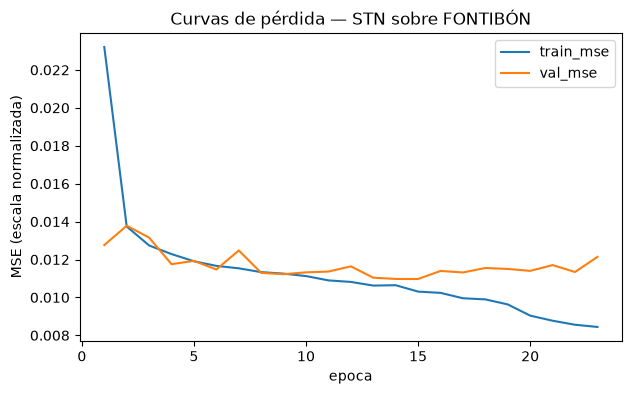

In [21]:
# Tabla final, en el mismo formato que la comparativa del cuaderno baseline
tabla_final = pd.DataFrame([
    {"fuente": "Beijing (paper) - STN",  "RMSE": 19.04, "MAE": 11.13, "R2": 0.937},
    {"fuente": "Taizhou (paper) - STN",  "RMSE": 5.79,  "MAE": 3.76,  "R2": 0.924},
    {"fuente": f"Bogotá {ESTACION} - Persistencia", **{k: pers_bog[k] for k in ("RMSE", "MAE", "R2")}},
    {"fuente": f"Bogotá {ESTACION} - STN",          **{k: m_bog[k]   for k in ("RMSE", "MAE", "R2")}},
])
display(tabla_final)

ax = hist_bog.set_index("epoca")[["train_mse", "val_mse"]].plot(
    figsize=(7, 4), title="Curvas de pérdida — STN sobre FONTIBÓN")
ax.set_ylabel("MSE (escala normalizada)")

---
## Sección 9 (opcional): transfer learning Beijing → Bogotá

**Qué se hace:** se inicializan los pesos con el modelo entrenado en Beijing y se afina sobre Bogotá
con learning rate bajo. Solo se transfieren las capas cuyas formas coinciden; las de entrada y salida
se reinicializan, porque el número y el significado de las variables difieren.

**Hipótesis nula explícita:** esto **no** mejora el resultado de la Sección 8. Correrlo igual tiene
valor: un resultado negativo bien medido es un hallazgo reportable ("la transferencia entre regímenes
de contaminación tan distintos no aporta"), y un resultado positivo sería interesante de verdad. Lo
que no corresponde es presentarlo como el método principal.

In [22]:
if Path("ckpt_beijing.pt").exists():
    estado_bj = torch.load("ckpt_beijing.pt", map_location=DEVICE)
    cfg_tl = {**cfg_final, "lr": 1e-5}          # lr bajo: afinar, no reescribir
    modelo_tl, m_tl, pers_tl, hist_tl = entrenar_stn(
        data_bog, cfg_tl, epochs=40, init_state=estado_bj,
        etiqueta="BOGOTÁ con preentrenamiento en Beijing")

    print("\nComparación directa:")
    print(f"  STN desde cero          : R2={m_bog['R2']:.4f}  RMSE={m_bog['RMSE']:.3f}")
    print(f"  STN preentrenado Beijing: R2={m_tl['R2']:.4f}  RMSE={m_tl['RMSE']:.3f}")
else:
    print("Primero corré la Sección 5 para generar ckpt_beijing.pt.")

Pesos compatibles cargados=4; omitidos por forma=161; faltantes=161.
Parámetros entrenables: 1,216,385
época   1 | train MSE 0.03564 | val MSE 0.01742
época   2 | train MSE 0.01944 | val MSE 0.01425
época   3 | train MSE 0.01640 | val MSE 0.01317
época   4 | train MSE 0.01504 | val MSE 0.01339
época   5 | train MSE 0.01424 | val MSE 0.01311
época   6 | train MSE 0.01384 | val MSE 0.01225
época   7 | train MSE 0.01342 | val MSE 0.01196
época   8 | train MSE 0.01312 | val MSE 0.01194
época   9 | train MSE 0.01285 | val MSE 0.01186
época  10 | train MSE 0.01265 | val MSE 0.01208
época  11 | train MSE 0.01247 | val MSE 0.01178
época  12 | train MSE 0.01244 | val MSE 0.01197
época  13 | train MSE 0.01226 | val MSE 0.01180
época  14 | train MSE 0.01214 | val MSE 0.01199
época  15 | train MSE 0.01204 | val MSE 0.01227
época  16 | train MSE 0.01189 | val MSE 0.01162
época  17 | train MSE 0.01183 | val MSE 0.01163
época  18 | train MSE 0.01179 | val MSE 0.01170
época  19 | train MSE 0.01180 | v

---
## Notas y próximos pasos

- **Multi-paso (Tablas 2–5 del paper).** Cambiá `PRED_LEN` a 6, 12, 24 o 48 y volvé a correr la
  Sección 8: el decoder ya es generativo, así que predice el horizonte completo de una vez, sin
  autorregresión. Ojo con un detalle del paper: para horizontes mayores a 6 h, los autores parten el
  horizonte en intervalos y entrenan **modelos independientes por intervalo**, promediando después.
  Ese es exactamente el atajo que marcaste como injusto en la guía teórica — si lo replicás, replicalo
  señalando la objeción; si no, aclará que tu h24 es un único modelo y por eso no es comparable
  uno a uno con el 0.78 del paper.
- **Ablación del encoder de dos ramas.** `two_branch=False` en `construir_modelo` deja un encoder
  clásico tipo Informer. Es la forma de medir cuánto aporta realmente la contribución arquitectónica
  del paper sobre tus datos.
- **Qué fase de datos usar.** Este cuaderno interpola linealmente, como el paper. Si querés conectar
  con las Fases 1/2 del baseline (MissForest, con o sin grafo de vecinos), pasale a `prepare` la tabla
  ancha ya imputada en lugar del parquet crudo: `load_bogota` acepta un parquet ancho con índice de
  fecha, que es exactamente el formato de tu caché de imputación.
- **Honestidad sobre la réplica.** En la tesis conviene decir explícitamente: no hay código oficial
  del STN; esta es una reimplementación a partir de la descripción del paper y de Informer, validada
  reproduciendo el resultado publicado en Beijing. Es más defendible que presentarla como "el modelo
  del paper" a secas.